In [1]:
import pandas as pd
import re
import numpy as np

# File processing
from pathlib import Path

# Data viz
import seaborn as sns
import matplotlib.pyplot as plt

## Bedtools

In [2]:
from pybedtools import BedTool
from pybedtools.helpers import cleanup as bedtools_cleanup
from pybedtools.helpers import set_tempdir

In [3]:
bedtools_cleanup()

In [4]:
# https://github.com/daler/pybedtools/issues/252
def is_valid_bedtools(a):
    '''Does not work for BedTool from iterable'''
    try:
        ft = a.file_type
        if ft == 'empty':
            print("empty file!")
        else:
            print(f'input is {ft} - OK!')
    except IndexError:
        print('bad input!')

    

In [5]:
def extract_id_gff(x):
    m = re.match(r".*ID=(.*?);", x)
    if m:
        return m.groups()[0]
    else:
        print(x)

In [6]:
def id_filter(feature, ids):
    '''any feature with "ID" in list'''
    return feature.attrs["ID"] in ids

def type_filter(feature, t):
    ''' any features of type t'''
    return feature[2] == t

# https://github.com/daler/gffutils/blob/32e48a1b2c032cb2442286ec4e198a50e04c5c8c/gffutils/pybedtools_integration.py#L188
from pybedtools.featurefuncs import five_prime
def generate_tss_intervals(bed, upstream=0, downstream=1):
    for gene in bed.features():
        yield five_prime(gene, upstream=upstream, downstream=downstream)

## File paths

In [7]:
base_dir = Path("../")
data_dir = base_dir / "raw_data"
parsed_data_dir = base_dir / "parsed_data"
ref_data_dir = Path("../../reference_files/")

#### Bedtools tmpdir

In [8]:
bedtools_tmp = data_dir / "bedtools_tmp"
bedtools_tmp.mkdir(parents=True, exist_ok=True)
set_tempdir(bedtools_tmp)

# Load

In [9]:
gff_columns = [
    "seqname", 
    "source", 
    "feature", 
    "start", 
    "end", 
    "score", 
    "strand", 
    "frame", 
    "attribute"
] 

sga_columns = [
    "seqname",    # -   Chromosome (RefSeq or GenBank identifier in EPDnew)
    "feature",    # -   Feature type (always TSS in EPDnew)
    "start",      # -   Position in the chromosome
    "end",        # -   Strand (+ or -)
    "count",      # -   Count field (always 1 in EPDnew)
    "promotor"    # -   Annotation field (promoter entry Id in EPDnew)
]

Compare gene, UTR, EPD

### Araport

In [10]:
araport_file = ref_data_dir / "Araport11_GFF3_genes_transposons.current_utf8.gff.gz"
araport_gff = BedTool(araport_file)
is_valid_bedtools(araport_gff)
len(araport_gff)

input is gff - OK!


927373

In [76]:
araport_gff.head(10)

#chromosome assembly: TAIR10.1
 #genome annotation (gene structure): Araport11
 #symbol and full name data generated: 2024-01-02 by TAIR
 ##gff-3
 
 Chr1	Araport11	gene	3631	5899	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding
 Chr1	Araport11	mRNA	3631	5899	.	+	.	ID=AT1G01010.1;Name=AT1G01010.1,Parent=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1,curator_summary=Member of the NAC domain containing family of plant specific transcriptional regulators.;symbol=NAC001;Note=NAC domain containing protein 1,conf_rating=conf_rating=****;Dbxref=TAIR:2200934;Dbxref=UniProt:Q0WV96
 Chr1	Araport11	CDS	3760	3913	.	+	0	ID=AT1G01010:CDS:1;Name=NAC001:CDS:1,Parent=AT1G01010.1;computational_description=NAC domain containi

In [12]:
araport_gene_start = BedTool(generate_tss_intervals(araport_gff.filter(type_filter, "gene"))).sort()
araport_gene_start.head(1)

Chr1	Araport11	gene	3631	3631	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding
 

In [13]:
len(araport_gene_start)

33243

In [75]:
araport_5utr_start = BedTool(generate_tss_intervals(araport_gff.filter(type_filter, "five_prime_UTR"))).sort()
araport_5utr_start.head(5)

Chr1	Araport11	five_prime_UTR	3631	3631	.	+	.	ID=AT1G01010:five_prime_UTR:1;Name=NAC001:five_prime_UTR:1,Parent=AT1G01010.1;computational_description=NAC domain containing protein 1,curator_summary=Member of the NAC domain containing family of plant specific transcriptional regulators.;Note=NAC domain containing protein 1
 Chr1	Araport11	five_prime_UTR	8464	8464	.	-	.	ID=AT1G01020:five_prime_UTR:6;Name=ARV1:five_prime_UTR:6,Parent=AT1G01020.3;computational_description=ARV1 family protein,curator_summary=None;Note=Arv1-like protein
 Chr1	Araport11	five_prime_UTR	8464	8464	.	-	.	ID=AT1G01020:five_prime_UTR:6;Name=ARV1:five_prime_UTR:6,Parent=AT1G01020.4;computational_description=ARV1 family protein,curator_summary=None;Note=Arv1-like protein
 Chr1	Araport11	five_prime_UTR	8464	8464	.	-	.	ID=AT1G01020:five_prime_UTR:7;Name=ARV1:five_prime_UTR:7,Parent=AT1G01020.6;computational_description=ARV1 family protein,curator_summary=None;Note=Arv1-like protein
 Chr1	Araport11	five_prime_UTR	8464	8

In [77]:
len(araport_5utr_start)

56410

In [78]:
df_araport_gene  = araport_gene_start.to_dataframe(names=gff_columns)
df_araport_gene["geneID"] = df_araport_gene["attribute"].apply(extract_id_gff)
df_araport_gene

,seqname,source,feature,start,end,score,strand,frame,attribute,geneID
0,Chr1,Araport11,gene,3631,3631,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,AT1G01010
1,Chr1,Araport11,gene,9130,9130,.,-,.,ID=AT1G01020;Name=AT1G01020;computational_desc...,AT1G01020
2,Chr1,Araport11,gene,11101,11101,.,+,.,ID=AT1G03987;Name=AT1G03987;locus_type=long_no...,AT1G03987
3,Chr1,Araport11,gene,13714,13714,.,-,.,ID=AT1G01030;Name=AT1G01030;full_name=NGATHA3;...,AT1G01030
4,Chr1,Araport11,gene,23121,23121,.,+,.,ID=AT1G01040;Name=AT1G01040;full_name=dicer-li...,AT1G01040
...,...,...,...,...,...,...,...,...,...,...
33238,ChrM,Araport11,gene,321438,321438,.,-,.,ID=ATMG00800;Name=trnE(TTC);Note=None;locus_ty...,ATMG00800
33239,ChrM,Araport11,gene,321945,321945,.,-,.,ID=ATMG00780;Name=trnS(GCT);Note=None;locus_ty...,ATMG00780
33240,ChrM,Araport11,gene,330773,330773,.,-,.,ID=ATMG00735;Name=cox3;locus_type=protein_coding,ATMG00735
33241,ChrM,Araport11,gene,346454,346454,.,+,.,ID=ATMG00700;Name=trnK(TTT);Note=None;locus_ty...,ATMG00700


In [79]:
df_araport_gene = df_araport_gene[['seqname', 'start', 'strand', 'geneID']]

In [80]:
df_araport_5utr  = araport_5utr_start.to_dataframe(names=gff_columns)
df_araport_5utr["5utrID"] = df_araport_5utr["attribute"].apply(extract_id_gff)
df_araport_5utr["geneID"] = df_araport_5utr["5utrID"].apply(lambda x: x.split(":")[0])
df_araport_5utr

,seqname,source,feature,start,end,score,strand,frame,attribute,5utrID,geneID
0,Chr1,Araport11,five_prime_UTR,3631,3631,.,+,.,ID=AT1G01010:five_prime_UTR:1;Name=NAC001:five...,AT1G01010:five_prime_UTR:1,AT1G01010
1,Chr1,Araport11,five_prime_UTR,8464,8464,.,-,.,ID=AT1G01020:five_prime_UTR:6;Name=ARV1:five_p...,AT1G01020:five_prime_UTR:6,AT1G01020
2,Chr1,Araport11,five_prime_UTR,8464,8464,.,-,.,ID=AT1G01020:five_prime_UTR:6;Name=ARV1:five_p...,AT1G01020:five_prime_UTR:6,AT1G01020
3,Chr1,Araport11,five_prime_UTR,8464,8464,.,-,.,ID=AT1G01020:five_prime_UTR:7;Name=ARV1:five_p...,AT1G01020:five_prime_UTR:7,AT1G01020
4,Chr1,Araport11,five_prime_UTR,8464,8464,.,-,.,ID=AT1G01020:five_prime_UTR:7;Name=ARV1:five_p...,AT1G01020:five_prime_UTR:7,AT1G01020
...,...,...,...,...,...,...,...,...,...,...,...
56405,Chr5,Araport11,five_prime_UTR,26963638,26963638,.,-,.,ID=AT5G67610:five_prime_UTR:2;Name=AT5G67610:f...,AT5G67610:five_prime_UTR:2,AT5G67610
56406,Chr5,Araport11,five_prime_UTR,26963736,26963736,.,-,.,ID=AT5G67610:five_prime_UTR:1;Name=AT5G67610:f...,AT5G67610:five_prime_UTR:1,AT5G67610
56407,Chr5,Araport11,five_prime_UTR,26966010,26966010,.,-,.,ID=AT5G67620:five_prime_UTR:1;Name=AT5G67620:f...,AT5G67620:five_prime_UTR:1,AT5G67620
56408,Chr5,Araport11,five_prime_UTR,26969400,26969400,.,-,.,ID=AT5G67630:five_prime_UTR:1;Name=AT5G67630:f...,AT5G67630:five_prime_UTR:1,AT5G67630


In [81]:
df_araport_5utr[df_araport_5utr.duplicated(subset=["geneID", "start", "end"], keep=False)]
# (on keep=False)

,seqname,source,feature,start,end,score,strand,frame,attribute,5utrID,geneID
1,Chr1,Araport11,five_prime_UTR,8464,8464,.,-,.,ID=AT1G01020:five_prime_UTR:6;Name=ARV1:five_p...,AT1G01020:five_prime_UTR:6,AT1G01020
2,Chr1,Araport11,five_prime_UTR,8464,8464,.,-,.,ID=AT1G01020:five_prime_UTR:6;Name=ARV1:five_p...,AT1G01020:five_prime_UTR:6,AT1G01020
3,Chr1,Araport11,five_prime_UTR,8464,8464,.,-,.,ID=AT1G01020:five_prime_UTR:7;Name=ARV1:five_p...,AT1G01020:five_prime_UTR:7,AT1G01020
4,Chr1,Araport11,five_prime_UTR,8464,8464,.,-,.,ID=AT1G01020:five_prime_UTR:7;Name=ARV1:five_p...,AT1G01020:five_prime_UTR:7,AT1G01020
5,Chr1,Araport11,five_prime_UTR,8737,8737,.,-,.,ID=AT1G01020:five_prime_UTR:2;Name=ARV1:five_p...,AT1G01020:five_prime_UTR:2,AT1G01020
...,...,...,...,...,...,...,...,...,...,...,...
56390,Chr5,Araport11,five_prime_UTR,26939159,26939159,.,+,.,ID=AT5G67520:five_prime_UTR:1;Name=APK4:five_p...,AT5G67520:five_prime_UTR:1,AT5G67520
56394,Chr5,Araport11,five_prime_UTR,26946377,26946377,.,-,.,ID=AT5G67540:five_prime_UTR:1;Name=AT5G67540:f...,AT5G67540:five_prime_UTR:1,AT5G67540
56395,Chr5,Araport11,five_prime_UTR,26946377,26946377,.,-,.,ID=AT5G67540:five_prime_UTR:2;Name=AT5G67540:f...,AT5G67540:five_prime_UTR:2,AT5G67540
56399,Chr5,Araport11,five_prime_UTR,26957107,26957107,.,-,.,ID=AT5G67580:five_prime_UTR:3;Name=TRB2:five_p...,AT5G67580:five_prime_UTR:3,AT5G67580


In [82]:
df_araport_5utr.drop_duplicates(subset=["geneID", "start", "end"], inplace=True)
df_araport_5utr.shape

(43999, 11)

In [83]:
df_araport_5utr.columns

Index(['seqname', 'source', 'feature', 'start', 'end', 'score', 'strand',
       'frame', 'attribute', '5utrID', 'geneID'],
      dtype='object')

In [84]:
df_araport_5utr = df_araport_5utr[['seqname', 'start', 'strand', '5utrID', 'geneID']]

In [85]:
df_compare = df_araport_5utr.join(
    df_araport_gene.set_index("geneID")[["start"]], 
    on="geneID",
    lsuffix="_5utr", rsuffix="_gene", 
    how="left"
)

df_compare

,seqname,start_5utr,strand,5utrID,geneID,start_gene
0,Chr1,3631,+,AT1G01010:five_prime_UTR:1,AT1G01010,3631
1,Chr1,8464,-,AT1G01020:five_prime_UTR:6,AT1G01020,9130
5,Chr1,8737,-,AT1G01020:five_prime_UTR:2,AT1G01020,9130
7,Chr1,9130,-,AT1G01020:five_prime_UTR:1,AT1G01020,9130
11,Chr1,13173,-,AT1G01030:five_prime_UTR:2,AT1G01030,13714
...,...,...,...,...,...,...
56405,Chr5,26963638,-,AT5G67610:five_prime_UTR:2,AT5G67610,26963736
56406,Chr5,26963736,-,AT5G67610:five_prime_UTR:1,AT5G67610,26963736
56407,Chr5,26966010,-,AT5G67620:five_prime_UTR:1,AT5G67620,26966010
56408,Chr5,26969400,-,AT5G67630:five_prime_UTR:1,AT5G67630,26969400


## EPD

In [86]:
df_epd = pd.read_csv(data_dir / "At_EPDnew.sga", sep="\t", header=None, names=sga_columns)
df_epd.head()

,seqname,feature,start,end,count,promotor
0,NC_003070.9,TSS,3631,+,1,AT1G01010_1
1,NC_003070.9,TSS,8713,-,1,AT1G01020_1
2,NC_003070.9,TSS,13777,-,1,AT1G01030_1
3,NC_003070.9,TSS,23135,+,1,AT1G01040_1
4,NC_003070.9,TSS,33117,-,1,AT1G01050_1


In [87]:
df_epd[df_epd["promotor"].duplicated(keep=False)]

,seqname,feature,start,end,count,promotor


In [88]:
df_epd["geneID"] = df_epd["promotor"].apply(lambda x: x.split("_")[0])
df_epd.head()

,seqname,feature,start,end,count,promotor,geneID
0,NC_003070.9,TSS,3631,+,1,AT1G01010_1,AT1G01010
1,NC_003070.9,TSS,8713,-,1,AT1G01020_1,AT1G01020
2,NC_003070.9,TSS,13777,-,1,AT1G01030_1,AT1G01030
3,NC_003070.9,TSS,23135,+,1,AT1G01040_1,AT1G01040
4,NC_003070.9,TSS,33117,-,1,AT1G01050_1,AT1G01050


In [89]:
df_epd[df_epd["geneID"].duplicated(keep=False)]

,seqname,feature,start,end,count,promotor,geneID
13464,NC_003074.8,TSS,21346741,+,1,ATH_U22_1,ATH
17745,NC_003076.8,TSS,1319131,+,1,ATH_SIR_1,ATH
18186,NC_003076.8,TSS,2975012,+,1,ATH_U25_1,ATH


In [90]:
df_epd = df_epd.set_index("geneID")[["start"]]
df_epd.columns = ["start_epd"]
df_epd.head()

,start_epd
geneID,
AT1G01010,3631
AT1G01020,8713
AT1G01030,13777
AT1G01040,23135
AT1G01050,33117


In [91]:
df_compare = df_compare.join(df_epd, on="geneID")

In [92]:
df_compare = df_compare[~df_compare["seqname"].isna()]

# Distances

In [93]:
def distance_ab(x, a, b):
    strand = x["strand"]

    # overlaps
    if x[a] == x[b]:
        return 0
    
    if strand == "+" or strand == ".":
        return x[a] - x[b]
    else:
        return -(x[a] - x[b])
    

In [94]:
df_compare["gene_5utr_difference"] = df_compare.apply(distance_ab, a="start_gene", b="start_5utr", axis=1)
df_compare["gene_epd_difference"] = df_compare.apply(distance_ab, a="start_gene", b="start_epd", axis=1)
df_compare["5utr_epd_difference"] = df_compare.apply(distance_ab, a="start_5utr", b="start_epd", axis=1)

In [95]:
def print_stats(X, decimals=2):
    stats = [
        ("min", X.min()),
        ("max", X.max()),
        ("mean", X.mean()),
        ("median:", X.median()),
        
        ("lower quantile (25) ", X.quantile(0.25)),
        ("upper quantile (75) ", X.quantile(0.75)),
        ("number", X.shape[0])
    ]

    display(pd.DataFrame(stats, columns=["stat", "value"]).round(decimals).style.format({"value":"{:,}"}))


gene_5utr_difference 43999


,stat,value
0,min,"-13,805.0"
1,max,0.0
2,mean,-186.32
3,median:,0.0
4,lower quantile (25),-210.0
5,upper quantile (75),0.0
6,number,"43,999.0"


gene_epd_difference 23592


,stat,value
0,min,"-26,852.0"
1,max,"194,828.0"
2,mean,-90.71
3,median:,-87.0
4,lower quantile (25),-166.0
5,upper quantile (75),-36.0
6,number,"23,592.0"


5utr_epd_difference 43999


,stat,value
0,min,"-26,852.0"
1,max,"194,828.0"
2,mean,81.58
3,median:,-41.0
4,lower quantile (25),-117.0
5,upper quantile (75),17.0
6,number,"43,999.0"


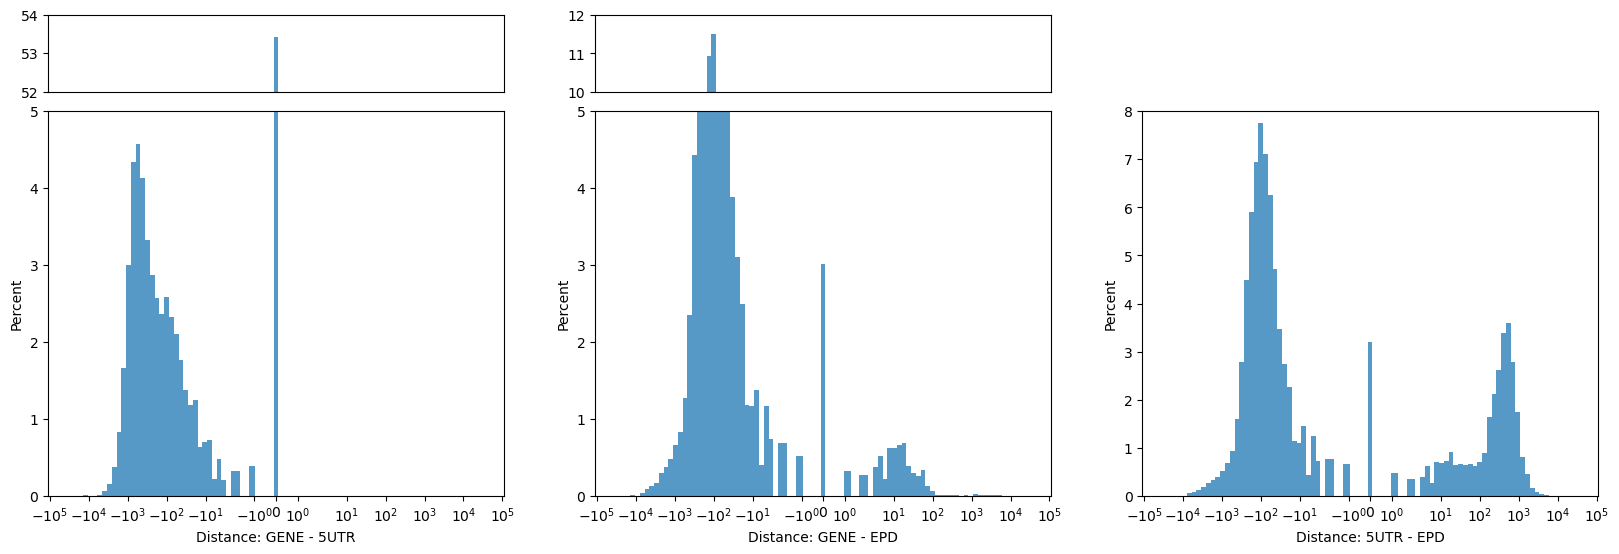

In [98]:
bins=np.logspace(np.log10(0.1),np.log10(100000.0), 50)
bins = np.concatenate((-bins[::-1], bins))

axis_lims = {
    "gene_5utr_difference": (0, 5, 52, 54), 
    "gene_epd_difference": (0, 5, 10, 12), 
    "5utr_epd_difference": (0, 8), 
}

mfig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 5))
for (i, c), ax in zip([("5utrID", "gene_5utr_difference"), ("geneID", "gene_epd_difference"), ("5utrID", "5utr_epd_difference")], axes):

    df = df_compare[[i, c]].drop_duplicates(keep="first")
    print(c, df.shape[0])
    print_stats(df[c])

    sns.histplot(df, x=c, bins=bins, ax=ax, stat="percent")
    ax.set_xscale("symlog")
    lims = axis_lims[c]

    cparts = c.split("_")
    ax.set_xlabel(f"Distance: {cparts[0].upper()} - {cparts[1].upper()}")
    if len(lims)>2:
        ax2 = ax.inset_axes(bounds=[0, 1.05, 1, 0.2])
        sns.histplot(df, x=c, bins=bins, ax=ax2, stat="percent")
        ax2.set_xscale("symlog")

        ax2.set_ylim(lims[2], lims[3])
        ax2.set_ylabel(None)
        
        ax2.set_xticks([])
        ax2.set_xticks([], minor=True)
        ax2.tick_params(bottom=False)
        ax2.set_xlabel(None)

    
    ax.set_ylim(lims[0], lims[1])




In [73]:
cparts

['5utr', 'epd', 'difference']

In [131]:
closet_epd_per_gene = df_compare.loc[df_compare.groupby("geneID")["5utr_epd_difference"].idxmin()]
_ = [print(x, end=", ") for x in closet_epd_per_gene[closet_epd_per_gene["5utr_epd_difference"]>=10000]["geneID"].values]

AT1G17440, AT1G31550, AT1G65540, AT1G75940, AT2G25050, AT3G08720, AT3G08850, AT3G09260, AT3G59690, AT5G34850, AT5G66620, 

In [130]:
closet_epd_per_gene[closet_epd_per_gene["5utr_epd_difference"]>=5000]

,seqname,start_5utr,strand,5utrID,geneID,start_gene,start_epd,gene_5utr_difference,gene_epd_difference,5utr_epd_difference
4281,Chr1,5987934,-,AT1G17440:five_prime_UTR:1,AT1G17440,5987934,6173137.0,0,185203.0,185203.0
4708,Chr1,6768158,-,AT1G19550:five_prime_UTR:1,AT1G19550,6768158,6774455.0,0,6297.0,6297.0
6949,Chr1,11297379,-,AT1G31550:five_prime_UTR:1,AT1G31550,11297379,11412153.0,0,114774.0,114774.0
11514,Chr1,24366466,-,AT1G65540:five_prime_UTR:2,AT1G65540,24366466,24529294.0,0,162828.0,162828.0
13633,Chr1,28511142,+,AT1G75940:five_prime_UTR:1,AT1G75940,28511142,28334941.0,0,176201.0,176201.0
18321,Chr2,10660558,-,AT2G25050:five_prime_UTR:1,AT2G25050,10660558,10831617.0,0,171059.0,171059.0
25712,Chr3,2651231,-,AT3G08720:five_prime_UTR:1,AT3G08720,2651231,2843775.0,0,192544.0,192544.0
25746,Chr3,2695400,-,AT3G08850:five_prime_UTR:1,AT3G08850,2695400,2890228.0,0,194828.0,194828.0
25846,Chr3,2843781,-,AT3G09260:five_prime_UTR:1,AT3G09260,2843781,2872023.0,0,28242.0,28242.0
34112,Chr3,22048557,+,AT3G59690:five_prime_UTR:1,AT3G59690,22048557,21975637.0,0,72920.0,72920.0


In [119]:
df_compare[(df_compare["5utr_epd_difference"]>=5000)]# & (df_compare["gene_epd_difference"]>=5000)]

,seqname,start_5utr,strand,5utrID,geneID,start_gene,start_epd,gene_5utr_difference,gene_epd_difference,5utr_epd_difference
4280,Chr1,5987771,-,AT1G17440:five_prime_UTR:2,AT1G17440,5987934,6173137.0,-163,185203.0,185366.0
4281,Chr1,5987934,-,AT1G17440:five_prime_UTR:1,AT1G17440,5987934,6173137.0,0,185203.0,185203.0
4708,Chr1,6768158,-,AT1G19550:five_prime_UTR:1,AT1G19550,6768158,6774455.0,0,6297.0,6297.0
6949,Chr1,11297379,-,AT1G31550:five_prime_UTR:1,AT1G31550,11297379,11412153.0,0,114774.0,114774.0
10173,Chr1,21753884,+,AT1G58602:five_prime_UTR:3,AT1G58602,21746354,21746329.0,-7530,25.0,7555.0
10175,Chr1,21758509,+,AT1G58602:five_prime_UTR:4,AT1G58602,21746354,21746329.0,-12155,25.0,12180.0
10177,Chr1,21760159,+,AT1G58602:five_prime_UTR:5,AT1G58602,21746354,21746329.0,-13805,25.0,13830.0
11509,Chr1,24366065,-,AT1G65540:five_prime_UTR:4,AT1G65540,24366466,24529294.0,-401,162828.0,163229.0
11511,Chr1,24366089,-,AT1G65540:five_prime_UTR:3,AT1G65540,24366466,24529294.0,-377,162828.0,163205.0
11512,Chr1,24366456,-,AT1G65540:five_prime_UTR:1,AT1G65540,24366466,24529294.0,-10,162828.0,162838.0


In [106]:
df_compare[(df_compare["5utr_epd_difference"]>=5000) & (df_compare["gene_epd_difference"]>=5000)]["geneID"].value_counts()

geneID
AT3G08720    6
AT1G65540    4
AT5G66620    4
AT3G59690    3
AT1G17440    2
AT5G34850    2
AT1G19550    1
AT1G31550    1
AT1G75940    1
AT2G25050    1
AT3G08850    1
AT3G09260    1
AT4G33840    1
Name: count, dtype: int64

In [67]:
df_compare[df_compare["geneID"]=="AT1G75940"]

,seqname,start_5utr,strand,5utrID,geneID,start_gene,start_epd,gene_5utr_difference,gene_epd_difference,5utr_epd_difference
13633,Chr1,28511142,+,AT1G75940:five_prime_UTR:1,AT1G75940,28511142,28334941.0,0,176201.0,176201.0


In [117]:
df_compare[df_compare["geneID"]=="AT5G03360"]

,seqname,start_5utr,strand,5utrID,geneID,start_gene,start_epd,gene_5utr_difference,gene_epd_difference,5utr_epd_difference
44064,Chr5,822077,+,AT5G03360:five_prime_UTR:1,AT5G03360,822077,817831.0,0,4246.0,4246.0


In [52]:
import plotly.express as px
import plotly.graph_objects as go


import plotly.io as pio
pio.renderers.default = 'notebook'

import plotly.offline as pyo
pyo.init_notebook_mode(connected=True)

In [138]:
m = df_compare[["startEPD", "startGene"]].max(axis=None)
mi = df_compare[["startEPD", "startGene"]].min(axis=None)

fig = px.scatter(df_compare.reset_index(), x="startGene", y="startEPD", color="difference", facet_col="seqname", 
                 hover_data=['ID', 'startEPD', 'seqname', 'startGene', 'difference'], color_continuous_scale="RdBu", 
                range_color=[-5000, 5000], 
                width=3000, height=500,
                # log_x=True, log_y=True
                )

fig.update_traces(marker=dict(size=4,
                              line=dict(width=0.5,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))


fig.add_trace(
    go.Scatter(x=[0, m], y=[0, m], mode='lines', line={"color":'black'}), 
    col='all', row='all'
)


for v in [500, 1000, 5000, 20000]:
    fig.add_trace(
        go.Scatter(x=[0, m-v], y=[0-v, m], mode='lines', line={"color":'grey', "width":1}, name=f"-{v}"), 
        col='all', row='all'
    )
    fig.add_trace(
        go.Scatter(x=[0, m+v], y=[0+v, m], mode='lines', line={"color":'grey', "width":1}, name=f"+{v}"), 
        col='all', row='all'
    )
    print(v)
fig.update_layout(
    yaxis_scaleanchor="x",
)
fig.write_html("geneStart-vs-EPD.html")

/home/cbleker/miniconda3/envs/python-env/lib/python3.10/site-packages/plotly/express/_core.py:1979: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



500
1000
5000
20000


In [133]:
araport_tss_region = BedTool(generate_tss_intervals(araport_gff, upstream=5000, downstream=5000))
araport_tss_region = araport_tss_region.sort()

In [134]:
araport_tss_region.head(1)

Chr1	Araport11	gene	1	8630	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding
 

In [135]:
len(araport_tss_region)

33243

## Intersection with TSS "region"

In [140]:
# https://bedtools.readthedocs.io/en/latest/content/tools/intersect.html
# minimum overlap as fraction of A (dapseq): f=1
dapseq_intersection = dapseq_bed.intersect(araport_tss_region, f=1, wo=True)
print(len(dapseq_intersection))
dapseq_intersection.head(3)

2084193
Chr1	0	166	1:65_MYBrelated_tnt.TRP2_col_a	Chr1	Araport11	gene	1	8630	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	166
 Chr1	0	181	1:80_MYBrelated_tnt.TRP1_col	Chr1	Araport11	gene	1	8630	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	181
 Chr1	0	161	1:60_MYBrelated_tnt.AT1G72740_col_a	Chr1	Araport11	gene	1	8630	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxre

In [141]:
df_intersection  = dapseq_intersection.to_dataframe(names=[
    'chrom', 'start', 'end', 'name', # bed
    "seqname", "source", "feature", "gff_start", "gff_end", "score", "strand", "frame", "attributes", # gff
    "overlap"
])

In [142]:
df_intersection.head()

,chrom,start,end,name,seqname,source,feature,gff_start,gff_end,score,strand,frame,attributes,overlap
0,Chr1,0,166,1:65_MYBrelated_tnt.TRP2_col_a,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,166
1,Chr1,0,181,1:80_MYBrelated_tnt.TRP1_col,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,181
2,Chr1,0,161,1:60_MYBrelated_tnt.AT1G72740_col_a,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,161
3,Chr1,104,305,1:204_MYBrelated_tnt.EPR1_col,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,201
4,Chr1,105,306,1:205_MYBrelated_tnt.LHY1_col_a,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,201


In [143]:
len(set(df_intersection["name"]))

657563

In [144]:
df_intersection.shape

(2084193, 14)

In [145]:
df_intersection.groupby("name").size().value_counts()

3     179025
2     157600
4     135763
1      75530
5      68453
6      26489
7       9479
8       3222
9       1186
10       411
12       126
11       123
13        52
16        25
17        23
14        19
18        17
15        15
19         5
Name: count, dtype: int64

In [147]:
df_intersection["target"] = df_intersection["attributes"].apply(extract_id_gff)

In [148]:
df_intersection.tail()

,chrom,start,end,name,seqname,source,feature,gff_start,gff_end,score,strand,frame,attributes,overlap,target
2084188,Chr5,26975315,26975516,5:26975415_MYBrelated_tnt.TRP2_col_a,Chr5,Araport11,gene,26966389,26976388,.,+,.,ID=AT5G09955;Name=AT5G09955;locus_type=long_no...,201,AT5G09955
2084189,Chr5,26975315,26975516,5:26975415_MYBrelated_tnt.TRP2_col_a,Chr5,Araport11,gene,26967645,26977644,.,-,.,ID=AT5G09965;Name=AT5G09965;locus_type=long_no...,201,AT5G09965
2084190,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,Araport11,gene,26965669,26975668,.,-,.,ID=AT5G67640;Name=AT5G67640;Dbxref=TAIR:215866...,201,AT5G67640
2084191,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,Araport11,gene,26966389,26976388,.,+,.,ID=AT5G09955;Name=AT5G09955;locus_type=long_no...,201,AT5G09955
2084192,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,Araport11,gene,26967645,26977644,.,-,.,ID=AT5G09965;Name=AT5G09965;locus_type=long_no...,201,AT5G09965


## Closest TSS per peak only

__This is done extradinarily inefficiently... __

Closest is not the abosulte closest, because the acutal closest may not have the peak in its "region". 

Would be waaaay easier of we only did upstream or only downstream (bedtool closest function). 

Or upstream and downstream seperately, and prioritise after?

In [149]:
def name_filter(feature, l):
    return feature.attrs["ID"] in l


In [150]:
df_intersection = df_intersection[['chrom', 'start', 'end', 'name', 
                                   'seqname', 'strand', 'overlap', 'target']]

In [151]:
df_tss = pd.DataFrame(araport_tss.filter(name_filter, l=list(set(df_intersection["target"]))).saveas().to_dataframe()[["start", "attributes"]])
df_tss.shape

(32714, 2)

In [152]:
df_tss.columns = ["tss_site", "target_attributes"]

In [153]:
df_tss["ID"] = df_tss["target_attributes"].apply(extract_id_gff)

In [154]:
df_tss.head()

,tss_site,target_attributes,ID
0,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,AT1G01010
1,9130,ID=AT1G01020;Name=AT1G01020;computational_desc...,AT1G01020
2,11101,ID=AT1G03987;Name=AT1G03987;locus_type=long_no...,AT1G03987
3,13714,ID=AT1G01030;Name=AT1G01030;full_name=NGATHA3;...,AT1G01030
4,23121,ID=AT1G01040;Name=AT1G01040;full_name=dicer-li...,AT1G01040


In [155]:
df_intersection = df_intersection.join(df_tss.set_index("ID"), on="target", how="left")


In [156]:
df_intersection.head()

,chrom,start,end,name,seqname,strand,overlap,target,tss_site,target_attributes
0,Chr1,0,166,1:65_MYBrelated_tnt.TRP2_col_a,Chr1,+,166,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
1,Chr1,0,181,1:80_MYBrelated_tnt.TRP1_col,Chr1,+,181,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
2,Chr1,0,161,1:60_MYBrelated_tnt.AT1G72740_col_a,Chr1,+,161,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
3,Chr1,104,305,1:204_MYBrelated_tnt.EPR1_col,Chr1,+,201,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
4,Chr1,105,306,1:205_MYBrelated_tnt.LHY1_col_a,Chr1,+,201,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...


In [157]:
def distance_from_tss(x):
    strand = x["strand"]

    # overlaps
    if x["start"] <= x["tss_site"] <= x["end"]:
        return 0
    
    if strand == "+" or strand == ".":
        
        # peak is upstream, take tss - peak_end
        if x["end"] < x["tss_site"]:
            return x["end"] - x["tss_site"]
        
        # peak is downstream, take peak_start - tss
        elif x["start"] > x["tss_site"]:
            return x["start"] - x["tss_site"]

        # shouldn be here
        else:
            return pd.NA

    else:
        
        # peak is downstream, take tss - peak_end
        if x["end"] < x["tss_site"]:
            return x["tss_site"] - x["end"]
        
        # peak is upstream, take peak_start - tss
        elif x["start"] > x["tss_site"]:
            return x["tss_site"] - x["start"]

        # shouldn be here
        else:
            return pd.NA


        
    

In [158]:
df_intersection["distance"] = df_intersection.apply(distance_from_tss, axis=1)

In [159]:
df_intersection

,chrom,start,end,name,seqname,strand,overlap,target,tss_site,target_attributes,distance
0,Chr1,0,166,1:65_MYBrelated_tnt.TRP2_col_a,Chr1,+,166,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3465
1,Chr1,0,181,1:80_MYBrelated_tnt.TRP1_col,Chr1,+,181,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3450
2,Chr1,0,161,1:60_MYBrelated_tnt.AT1G72740_col_a,Chr1,+,161,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3470
3,Chr1,104,305,1:204_MYBrelated_tnt.EPR1_col,Chr1,+,201,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3326
4,Chr1,105,306,1:205_MYBrelated_tnt.LHY1_col_a,Chr1,+,201,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3325
...,...,...,...,...,...,...,...,...,...,...,...
2084188,Chr5,26975315,26975516,5:26975415_MYBrelated_tnt.TRP2_col_a,Chr5,+,201,AT5G09955,26971389,ID=AT5G09955;Name=AT5G09955;locus_type=long_no...,3926
2084189,Chr5,26975315,26975516,5:26975415_MYBrelated_tnt.TRP2_col_a,Chr5,-,201,AT5G09965,26972644,ID=AT5G09965;Name=AT5G09965;locus_type=long_no...,-2671
2084190,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,-,201,AT5G67640,26970668,ID=AT5G67640;Name=AT5G67640;Dbxref=TAIR:215866...,-4654
2084191,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,+,201,AT5G09955,26971389,ID=AT5G09955;Name=AT5G09955;locus_type=long_no...,3933


<Axes: xlabel='distance', ylabel='Count'>

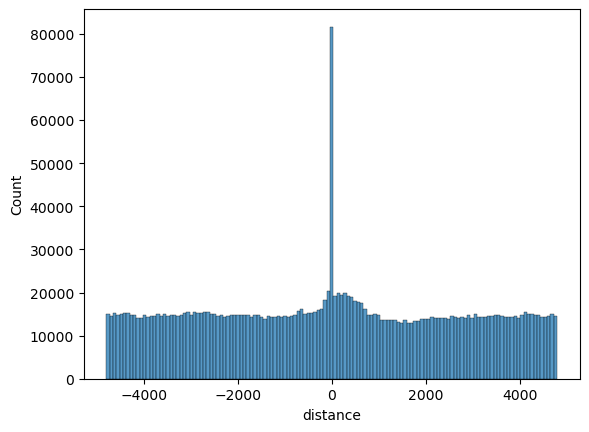

In [161]:
sns.histplot(df_intersection["distance"])

<Axes: xlabel='distance', ylabel='Count'>

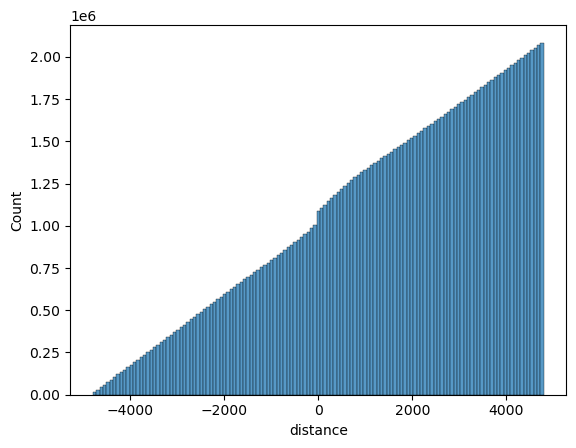

In [162]:
sns.histplot(df_intersection["distance"], cumulative=True)

In [179]:
df_intersection_min_per_peak = df_intersection.loc[df_intersection.groupby('name')['distance'].apply(lambda x: x.abs().idxmin())]

<Axes: xlabel='distance', ylabel='Count'>

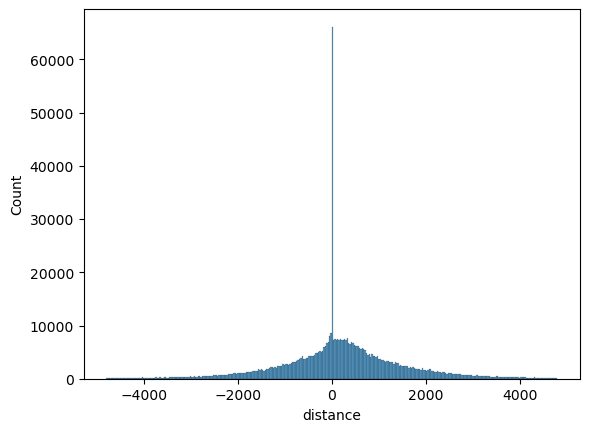

In [180]:
sns.histplot(df_intersection_min_per_peak["distance"])

<Axes: xlabel='distance', ylabel='Count'>

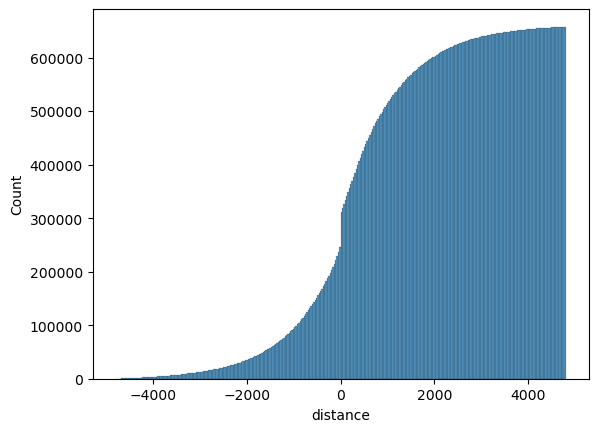

In [181]:
sns.histplot(df_intersection_min_per_peak["distance"], cumulative=True)

<Axes: xlabel='distance', ylabel='Percent'>

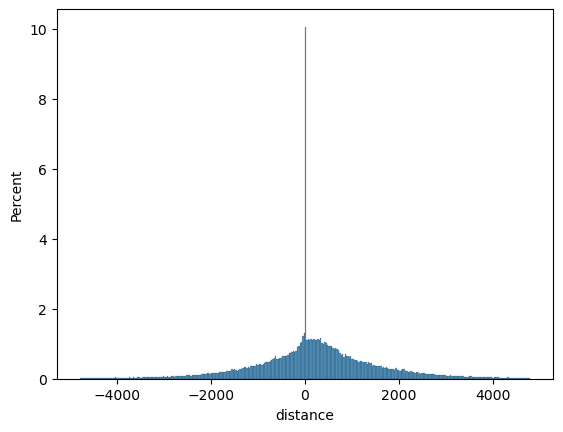

In [182]:
sns.histplot(df_intersection_min_per_peak["distance"], stat="percent")

(0.0, 1.5)

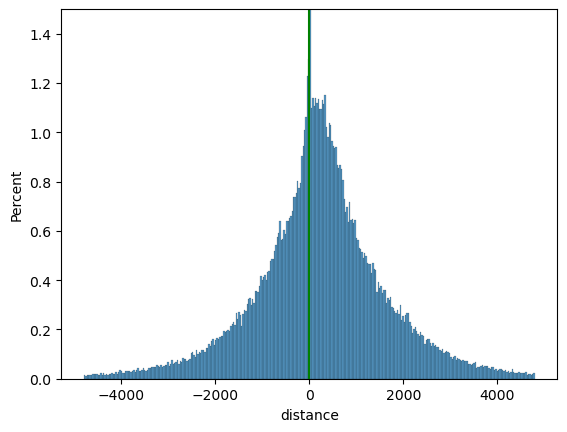

In [186]:
sns.histplot(df_intersection_min_per_peak["distance"], stat="percent")
plt.axvline(0, c="g")
plt.ylim([0, 1.5])

In [192]:
def apply_threshold(x, upstream, downstream):
    return upstream < x < downstream
    

In [193]:
df_intersection_min_per_peak_threshold = df_intersection[df_intersection['distance'].apply(apply_threshold, upstream=-2000, downstream=1000)]

<Axes: xlabel='distance', ylabel='Percent'>

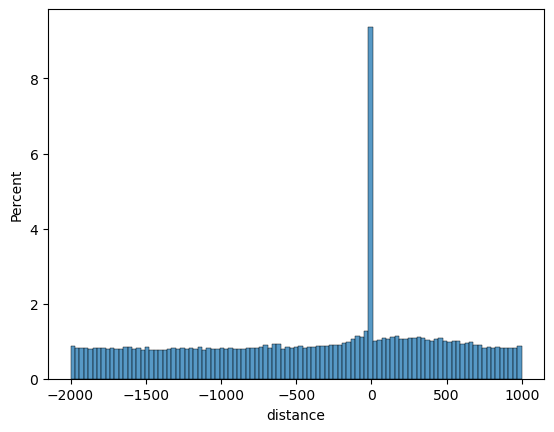

In [194]:
sns.histplot(df_intersection_min_per_peak_threshold["distance"], stat="percent")

(0.0, 1.5)

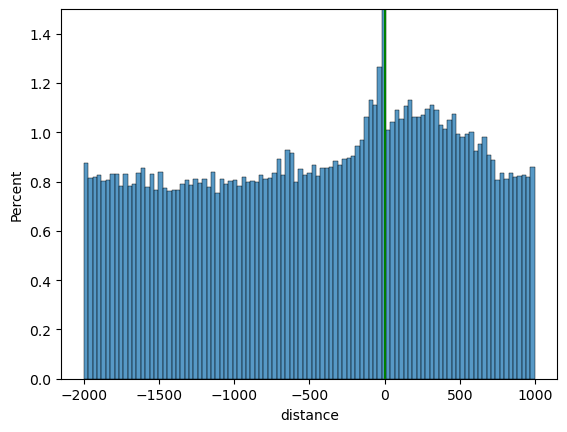

In [198]:
sns.histplot(df_intersection_min_per_peak_threshold["distance"], stat="percent")
plt.axvline(0, c="g")
plt.ylim([0, 1.5])

In [214]:
df_intersection_min_per_peak_threshold.shape

(740454, 11)

## Save results

In [205]:
df_intersection_min_per_peak_threshold.columns

Index(['chrom', 'start', 'end', 'name', 'seqname', 'strand', 'overlap',
       'target', 'tss_site', 'target_attributes', 'distance'],
      dtype='object')

In [208]:
sub_df.columns

Index(['chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand',
       'signalValue', 'pValue', 'qValue', 'peak', 'common title',
       'dna source'],
      dtype='object')

In [232]:
final_df = df_intersection_min_per_peak_threshold[["name", "target", "distance"]].set_index("name").join(
    sub_df[['name', 'signalValue', 'pValue', 'qValue', 'common title']].set_index('name'), 
    how="left"
)
final_df.reset_index(inplace=True)
final_df.head()

,name,target,distance,signalValue,pValue,qValue,common title
0,1:1539_bHLH_tnt.BIM2_col_v3b,AT1G01010,-1991,717.0,0.0,999.00,bHLH_tnt.BIM2_col_v3b
1,1:2126_WRKY_tnt.WRKY33_col_a,AT1G01010,-1404,77.0,0.0,39.72,WRKY_tnt.WRKY33_col_a
2,1:2341_MYBrelated_tnt.At1g49010_col_a,AT1G01010,-1189,109.0,0.0,45.40,MYBrelated_tnt.At1g49010_col_a
3,1:2566_C2C2dof_tnt.AT2G28810_col_a,AT1G01010,-964,240.0,0.0,138.02,C2C2dof_tnt.AT2G28810_col_a
4,1:2570_C2C2dof_tnt.OBP3_col_a,AT1G01010,-960,91.9,0.0,53.16,C2C2dof_tnt.OBP3_col_a


In [233]:
sample_df.columns

Index(['gene id', 'dna source', 'summary', 'taxon', 'protein',
       'protein family', 'protein affinity tag', 'expression system',
       'replicate', 'title', 'accession', 'file_name'],
      dtype='object')

In [234]:
final_df = final_df.join(sample_df[['gene id', 'dna source', 'protein',
       'protein family', 'protein affinity tag', 'expression system',
       'accession']], on="common title", how="left") 

In [235]:
final_df.columns

Index(['name', 'target', 'distance', 'signalValue', 'pValue', 'qValue',
       'common title', 'gene id', 'dna source', 'protein', 'protein family',
       'protein affinity tag', 'expression system', 'accession'],
      dtype='object')

In [236]:
final_df.columns = ['peak_name', 'target', 'peak_distance_tss', 'peak_signalValue', 'peak_pValue',
       'peak_qValue', 'library title', 'tf', 'dna source', 'tf protein', 'tf protein family', 'protein affinity tag',
       'expression system', 'accession']

In [237]:
final_df = final_df[['tf', 'target', 'peak_name', 'peak_distance_tss', 'peak_signalValue', 'peak_pValue',
       'peak_qValue', 'library title', 'tf', 'dna source', 'tf protein', 'tf protein family', 'protein affinity tag', 'expression system', 'accession']]

In [239]:
final_df.head()

,tf,target,peak_name,peak_distance_tss,peak_signalValue,peak_pValue,peak_qValue,library title,tf,dna source,tf protein,tf protein family,protein affinity tag,expression system,accession
0,AT1G69010,AT1G01010,1:1539_bHLH_tnt.BIM2_col_v3b,-1991,717.0,0.0,999.00,bHLH_tnt.BIM2_col_v3b,AT1G69010,col,BIM2,bHLH,Halo,tnt,GSM1925749
1,AT2G38470,AT1G01010,1:2126_WRKY_tnt.WRKY33_col_a,-1404,77.0,0.0,39.72,WRKY_tnt.WRKY33_col_a,AT2G38470,col,WRKY33,WRKY,Halo,tnt,GSM1925711
2,AT1G49010,AT1G01010,1:2341_MYBrelated_tnt.At1g49010_col_a,-1189,109.0,0.0,45.40,MYBrelated_tnt.At1g49010_col_a,AT1G49010,col,At1g49010,MYBrelated,Halo,tnt,GSM1925505
3,AT2G28810,AT1G01010,1:2566_C2C2dof_tnt.AT2G28810_col_a,-964,240.0,0.0,138.02,C2C2dof_tnt.AT2G28810_col_a,AT2G28810,col,AT2G28810,C2C2dof,Halo,tnt,GSM1925171
4,AT3G55370,AT1G01010,1:2570_C2C2dof_tnt.OBP3_col_a,-960,91.9,0.0,53.16,C2C2dof_tnt.OBP3_col_a,AT3G55370,col,OBP3,C2C2dof,Halo,tnt,GSM1925195


In [240]:
final_df.to_csv(parsed_data_dir / "dapseq_2000-1000_75.tsv", sep="\t", index=None)

In [241]:
# END

In [65]:
bedtools_cleanup()

In [66]:
araport_file = ref_data_dir / "Araport11_GFF3_genes_transposons.current_utf8_genes.gff.gz"
araport_gff = BedTool(araport_file)
is_valid_bedtools(araport_gff)
araport_gff = araport_gff.sort()
len(araport_gff)

input is gff - OK!


33243

In [67]:
araport_tss = BedTool(generate_tss_intervals(araport_gff))
araport_tss = araport_tss.sort()
araport_tss.head(1)

Chr1	Araport11	gene	3631	3631	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding
 

In [68]:
araport_tss.TEMPFILES = list(araport_tss.TEMPFILES)

In [73]:
def my_bedtools_cleanup(tmp_dir, keep_files=None):
    if keep_files is None:
        keep_files = []
    else:
        keep_files = [Path(x).name for x in keep_files]

    for f in tmp_dir.glob("pybedtools*"):
        if not (f.name in keep_files):
            f.unlink(missing_ok=True)


In [74]:
my_bedtools_cleanup(bedtools_tmp, keep_files=araport_tss.TEMPFILES)

In [75]:
def name_filter(feature, l):
    return feature.attrs["ID"] in l

def get_closest(peak_df, tss=None): 
    list_of_ids = peak_df["target"].to_list()

    if (list_of_ids) == 1:
        for x in BedTool([
                peak_df[["chrom", "start", "end", "name"]].iloc[0].values
            ]).absolute_distance(araport_tss.filter(name_filter, l=list_of_ids)):
            result = list_of_ids[0], x
    else:
        for x in BedTool([
                peak_df[["chrom", "start", "end", "name"]].iloc[0].values
            ]).closest(
                araport_tss.filter(name_filter, l=list_of_ids), D="b"
            ):
            result = extract_id_gff(x.fields[-2]), x.fields[-1]
    
    global i
    i += 1
    if i % 20 == 0:
        my_bedtools_cleanup(bedtools_tmp, keep_files=araport_tss.TEMPFILES)
        
    return pd.Series(result)

In [76]:
i = 0
closest_and_distances = df_intersection.groupby("name").apply(get_closest, tss=araport_tss, include_groups=True)

KeyboardInterrupt: 

In [ ]:
closest_and_distances.columns = ["target", "distance"]
closest_and_distances.to_csv(parsed_data_dir / "tf_target_3000_100.tsv", sep="\t")

In [ ]:
for name, peak_df in df_intersection.head(2000).groupby("name"):
    if peak_df.shape[0] > 1:
        list_of_ids = peak_df["target ID"].to_list()
        break

1:10003433_AP2EREBP_tnt.CBF1_col_a AT1G28450 -346


In [263]:
x.fields

['Chr1',
 '10003333',
 '10003534',
 'AT1G28450',
 'Chr1',
 'Araport11',
 'gene',
 '10003880',
 '10003880',
 '.',
 '+',
 '.',
 'ID=AT1G28450;Name=AT1G28450;full_name=AGAMOUS-like 58;computational_description=AGAMOUS-like 58;locus=2032543;locus_type=protein_coding;symbol=AGL58;Note=AGAMOUS-like 58;Dbxref=TAIR:2032543;',
 '-346']

In [ ]:
list_of_ids = peak_df["target ID"].to_list()
araport_tss.filter(name_filter, l=list_of_ids).closest()

In [194]:
; list_of_ids

['AT1G28450', 'AT1G28460']

In [195]:
araport_tss.file_type

'gff'

In [168]:
for feature in araport_tss:
    break

In [184]:
feature.attrs.keys()

dict_keys(['ID', 'Name', 'full_name', 'computational_description', 'locus', 'locus_type', 'symbol', 'Note', 'Dbxref'])

In [175]:
feature.attrs["ID"] in list_of_ids

False

<BedTool(/tmp/pybedtools.haemrkev.tmp)>

In [120]:
BedTool(peak_df).closest(araport_tss.filter(lambda x: x.attrs["ID"] in peak_df["target ID"]))

BEDToolsError: 
Command was:

	bedtools closest -b "" -a stdin

Error message was:
Error: Unable to open file . Exiting.


<BedTool(<generator object BedTool.filter.<locals>.<genexpr> at 0x7f8e315c69d0>)>

,start,attributes
0,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
1,9130,ID=AT1G01020;Name=AT1G01020;computational_desc...
2,11101,ID=AT1G03987;Name=AT1G03987;locus_type=long_no...
3,13714,ID=AT1G01030;Name=AT1G01030;full_name=NGATHA3;...
4,23121,ID=AT1G01040;Name=AT1G01040;full_name=dicer-li...
...,...,...
33238,321438,ID=ATMG00800;Name=trnE(TTC);Note=None;locus_ty...
33239,321945,ID=ATMG00780;Name=trnS(GCT);Note=None;locus_ty...
33240,330773,ID=ATMG00735;Name=cox3;locus_type=protein_coding
33241,346454,ID=ATMG00700;Name=trnK(TTT);Note=None;locus_ty...


In [70]:
df_intersection.groupby("name").size().value_counts()

1     288945
2     123401
3      26156
4       3698
5        558
6        133
7         59
8         40
9          4
10         2
Name: count, dtype: int64

In [362]:
# dapseq_closest = dapseq_intersection.closest(araport_tss, wo=True, D='b', k=15)

In [363]:
dapseq_closest.head()

Chr1	1319	1520	1:1419_MYB_tnt.MYB27_col_a	Chr1	Araport11	gene	1131	3730	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	201	Chr1	Araport11	gene	3631	3631	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	-2111
 Chr1	1319	1520	1:1419_MYB_tnt.MYB27_col_a	Chr1	Araport11	gene	1131	3730	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	20

In [365]:
df_closest  = dapseq_closest.to_dataframe(names=\
    ['chrom', 'start', 'end', 'name'] +\
    [f"{x}_intersection" for x in gff_columns]+\
    ["overlap"] +\
    [f"{x}_closest" for x in gff_columns]+\
    ["distance"]
)
df_closest.shape

ParserError: Error tokenizing data. C error: Expected 24 fields in line 4324271, saw 46


In [366]:
del df_closest

In [ ]:
len(set(df_closest["name"]))

In [358]:
df_closest = df_closest[df_closest["attribute_closest"] == df_closest["attribute_intersection"]]
df_closest.shape

(341211, 24)

In [359]:
df_closest.sort_values('distance', key=abs).groupby('name').first()

,chrom,start,end,seqname_intersection,source_intersection,feature_intersection,gff_start_intersection,gff_end_intersection,score_intersection,strand_intersection,...,seqname_closest,source_closest,feature_closest,gff_start_closest,gff_end_closest,score_closest,strand_closest,frame_closest,attribute_closest,distance
name,,,,,,,,,,,,,,,,,,,,,
1:10001682_NAC_tnt.ANAC034_col,Chr1,10001582,10001783,Chr1,Araport11,gene,10001380,10003979,.,+,...,Chr1,Araport11,gene,10003880,10003880,.,+,.,ID=AT1G28450;Name=AT1G28450;full_name=AGAMOUS-...,-2097.0
1:10003433_AP2EREBP_tnt.CBF1_col_a,Chr1,10003333,10003534,Chr1,Araport11,gene,10001380,10003979,.,+,...,Chr1,Araport11,gene,10003880,10003880,.,+,.,ID=AT1G28450;Name=AT1G28450;full_name=AGAMOUS-...,-346.0
1:1000565_C2H2_tnt.AT4G26030_col_a,Chr1,1000465,1000666,Chr1,Araport11,gene,998616,1001215,.,+,...,Chr1,Araport11,gene,1001116,1001116,.,+,.,ID=AT1G03920;Name=AT1G03920;computational_desc...,-450.0
1:1000768_C2C2dof_tnt.AT5G66940_col_a,Chr1,1000668,1000869,Chr1,Araport11,gene,998616,1001215,.,+,...,Chr1,Araport11,gene,1001116,1001116,.,+,.,ID=AT1G03920;Name=AT1G03920;computational_desc...,-247.0
1:10008632_CPP_tnt.SOL1_col,Chr1,10008532,10008733,Chr1,Araport11,gene,10007624,10010223,.,+,...,Chr1,Araport11,gene,10010124,10010124,.,+,.,ID=AT1G28470;Name=AT1G28470;full_name=NAC doma...,-1391.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4:995222_NAC_tnt.VND1_col_a,Chr4,995122,995323,Chr4,Araport11,gene,992940,995539,.,-,...,Chr4,Araport11,gene,993039,993039,.,-,.,ID=AT4G02270;Name=AT4G02270;full_name=root hai...,-2084.0
4:995222_bHLH_tnt.BIM2_col_v3b,Chr4,995122,995323,Chr4,Araport11,gene,992940,995539,.,-,...,Chr4,Araport11,gene,993039,993039,.,-,.,ID=AT4G02270;Name=AT4G02270;full_name=root hai...,-2084.0
4:995223_NAC_tnt.ANAC070_col,Chr4,995123,995324,Chr4,Araport11,gene,992940,995539,.,-,...,Chr4,Araport11,gene,993039,993039,.,-,.,ID=AT4G02270;Name=AT4G02270;full_name=root hai...,-2085.0


In [132]:
# https://daler.github.io/pybedtools/autodocs/pybedtools.bedtool.BedTool.closest.html
# For each feature in A, finds the closest feature (upstream or downstream) in B.
# 's=False' ignore strand, 
# 'D=b' Report the closest feature in B, and its distance to A as an extra column. Use negative distances to report upstream features.
# Report distance with respect to B, when B is on the - strand, "upstream" means A has a higher (start,stop).
b = dapseq_bed.closest(araport_gff, s=False, D="b")
b.head(5)

Chr1	105	306	1:205	Chr1	Araport11	gene	3631	5899	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	-3325
 Chr1	7301	7502	1:7401	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	0
 Chr1	8033	8234	1:8133	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	0
 Chr1	16227	16428	1:16327	Chr1	Araport11	gene	11649	13714	.	-	.	ID=AT1G01030;Name=AT1G01030;full_name=NGATHA3;computational_description=AP2/B3-like transcriptiona

In [102]:
len(b)

25877

In [133]:
b.count()

18703

In [134]:
b.field_count()

14

In [138]:
from pybedtools.featurefuncs import five_prime

In [139]:
five_prime(araport_gff)

TypeError: Argument 'feature' has incorrect type (expected pybedtools.cbedtools.Interval, got BedTool)

In [135]:
# Intergenic peaks
# Report overlaps between two feature files. A.intersect(B)
# 'wo' Write the original A and B entries plus the number of base pairs of overlap between the two features. 
#      Overlaps restricted by -f and -r. Only A features with overlap are reported.
# 'F=' Minimum overlap required as a fraction of B.
intergenic_obj = dapseq_bed.intersect(araport_gff, wo=True)
intergenic_obj.head(3)

Chr1	7301	7502	1:7401	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	201
 Chr1	8033	8234	1:8133	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	201
 Chr1	66701	66902	1:66801	Chr1	Araport11	gene	64166	67774	.	-	.	ID=AT1G01140;Name=AT1G01140;full_name=CBL-interacting protein kinase 9;computational_description=CBL-interacting protein kinase 9;locus=2035367;locus_type=protein_coding;curator_summary=Encodes a CBL-interacting protein kinase with similarity to SOS2;symbol=CIPK9;Note=CBL-interacting protein kinase 9;Dbxref=TAIR:2035367;locus_type=protein_coding	201
 

In [162]:
test

'MYBrelated_tnt.LHY1_col_a'